# 00 — Build the v2 dataset (run this ONCE)

**Why:** the first dataset (PlantVillage only: 3 crops, lab photos) cannot teach a model to say "this is not one of my leaves", and its random split leaks near-duplicate photos of the same leaf into test.

**What this notebook builds** (everything is saved to Google Drive as `plant-disease-v2/data_v2.zip`):

| Piece | Source | Used for |
|---|---|---|
| 10 in-scope classes (corn / grape / pepper) | PlantVillage | train / val / test |
| Field photos of the same classes | PlantDoc **uncropped photos + bounding boxes** (real-world, messy backgrounds): we crop leaves ourselves (padded) AND keep the whole photo | train / val, plus **`field_test`** (leaf crops) and **`scene_test`** (whole photos, like a user upload) |
| **`Other_or_not_leaf` class (#11)** | other PlantVillage crops, PlantDoc other crops, faces (LFW), flowers, textures | train / val / test |
| `Other` generic objects | Caltech101, **half of the categories** (vehicles, animals, indoor objects ...) | train / val / test of the Other class |
| **`ood_test`** (never seen in training) | Apple + Tomato leaves, Oxford pets, PlantDoc other-crop test photos, **Caltech101 object categories never used in training** | honest "unknown image" test |

**Leak-free split (decided HERE, once; notebooks 01-04 only read it):** near-duplicate PlantVillage photos are clustered with DINOv2 embeddings and whole clusters go to one split (`StratifiedGroupKFold`). PlantDoc is split **per source photo**, so crops of one photo never land in both train and test.

**Held-out species:** Apple and Tomato (PlantVillage *and* PlantDoc) are never used for training or validation. They appear only in `ood_test`, together with Oxford pets and the PlantDoc other-crop test photos.

**Re-runnable:** every cell can be re-run after a crash. Cell 2 caches PlantVillage on Drive so a new session does not need to download it again.

**Needs:** Colab GPU runtime and ~10 GB free disk. No Kaggle token: PlantVillage comes from the same GitHub repo as version 1 (or your cached `plant-ai/data/PlantVillage.tar` on Drive).

In [ ]:
import os, sys, json, shutil, random, re, zipfile, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "scikit-learn", "scipy"], check=True)
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image
from google.colab import drive
drive.mount("/content/drive")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = random.Random(SEED)

DRIVE_ROOT = Path("/content/drive/MyDrive/plant-disease-v2"); DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
WORK = Path("/content/work"); RAW = WORK / "raw"; RAW.mkdir(parents=True, exist_ok=True)
RAW_CACHE = DRIVE_ROOT / "raw_cache.tar"      # optional: made by the LAST cell, restores PlantDoc/Flowers/DTD/Pets/LFW downloads
if RAW_CACHE.exists() and not any(RAW.iterdir()):
    print("restoring raw downloads from the Drive cache..."); subprocess.run(["tar", "-xf", str(RAW_CACHE), "-C", str(RAW)], check=True)
OUT = Path("/content/data_v2")
if OUT.exists(): shutil.rmtree(OUT)
OUT.mkdir(parents=True)

IN_SCOPE = [
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn_(maize)___Common_rust_",
    "Corn_(maize)___Northern_Leaf_Blight",
    "Corn_(maize)___healthy",
    "Grape___Black_rot",
    "Grape___Esca_(Black_Measles)",
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)",
    "Grape___healthy",
    "Pepper,_bell___Bacterial_spot",
    "Pepper,_bell___healthy",
]
OTHER = "Other_or_not_leaf"
CLASS_NAMES = IN_SCOPE + [OTHER]

# ---- knobs ----
PV_OTHER_CAP_PER_CLASS = 100          # other-crop PlantVillage images per folder -> "Other" (train)
HELDOUT_PV_CROPS = {"Apple", "Tomato"} # NEVER used for training; only ood_test
HELDOUT_CAP_PER_CLASS = 60
CAP = {"lfw": 700, "flowers": 600, "dtd": 500, "pets_ood": 500}
# (GROUP_SIM is now chosen automatically in the split cell: the lowest threshold that leaves no giant near-duplicate group)
MAX_SHORT_SIDE = 320                   # shrink big field photos -> much faster training
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

Mounted at /content/drive


In [ ]:
# ---- PlantVillage: SAME source as version 1 (spMohanty GitHub repo, raw/color) - no Kaggle token needed ----
CACHE_PV   = True                                                   # save raw/color on Drive once -> later sessions skip the 2 GB download
CACHE_TAR  = DRIVE_ROOT / "PlantVillage_color.tar"
LEGACY_TAR = Path("/content/drive/MyDrive/plant-ai/data/PlantVillage.tar")   # your v1 cache (used if it exists)
PV_ROOT = Path("/content/PlantVillage-Dataset"); PV_DIR = PV_ROOT / "raw" / "color"

if PV_DIR.is_dir() and any(PV_DIR.iterdir()):
    print("PlantVillage already available.")
elif CACHE_TAR.exists():
    print("Extracting PlantVillage cache from Drive...")
    PV_DIR.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(["tar", "-xf", str(CACHE_TAR), "-C", str(PV_DIR.parent)], check=True)
elif LEGACY_TAR.exists():
    print("Extracting v1 cached PlantVillage from Drive...")
    subprocess.run(["tar", "-xf", str(LEGACY_TAR), "-C", "/content"], check=True)
else:
    print("Downloading PlantVillage from GitHub (~2 GB)...")
    shutil.rmtree(PV_ROOT, ignore_errors=True)
    r = subprocess.run(["git", "clone", "--depth", "1", "https://github.com/spMohanty/PlantVillage-Dataset.git", str(PV_ROOT)],
                       capture_output=True, text=True)
    print(r.stderr[-300:])
    if CACHE_PV and PV_DIR.is_dir():
        print("Caching raw/color on Drive for next time (a few minutes)...")
        try: subprocess.run(["tar", "-cf", str(CACHE_TAR), "-C", str(PV_DIR.parent), "color"], check=True)
        except Exception as e: print("cache failed (not important):", e); CACHE_TAR.unlink(missing_ok=True)
assert PV_DIR.is_dir(), f"{PV_DIR} not found - check the download/extraction above"
print("PlantVillage folder:", PV_DIR, "|", sum(1 for p in PV_DIR.iterdir() if p.is_dir()), "classes")


Extracting PlantVillage cache from Drive...
PlantVillage folder: /content/PlantVillage-Dataset/raw/color | 38 classes


In [ ]:
# ---- PlantDoc: use the ORIGINAL (uncropped) photos + bounding boxes ----
PD_MODE = "detection"   # "detection" = uncropped photos + boxes (recommended)  |  "cropped" = pre-cropped leaves (fallback)
PD_OD, PD_CROP = RAW / "PlantDoc_OD", RAW / "PlantDoc_cropped"

def clone(url, dst):
    r = subprocess.run(["git", "clone", "--depth", "1", url, str(dst)], capture_output=True, text=True)
    print(r.stdout, r.stderr[-200:]); return dst.exists()

OD_OK = False
if PD_MODE == "detection":
    OD_OK = clone("https://github.com/pratikkayal/PlantDoc-Object-Detection-Dataset.git", PD_OD)
    if OD_OK:
        n_xml = sum(1 for _ in PD_OD.rglob("*.xml"))
        n_img = sum(1 for p in PD_OD.rglob("*") if p.suffix.lower() in IMG_EXT)
        print("repo top level:", sorted(p.name for p in PD_OD.iterdir())[:20])
        print(f"annotation files: {n_xml} | images: {n_img}")
        OD_OK = n_xml > 0
CROP_OK = False
if not OD_OK:
    print("!! detection repo unusable -> falling back to the cropped PlantDoc repo")
    PD_MODE = "cropped"
    CROP_OK = clone("https://github.com/pratikkayal/PlantDoc-Dataset.git", PD_CROP)
print("PD_MODE =", PD_MODE)

 ing files:  96% (4992/5200)
Updating files:  97% (5044/5200)
Updating files:  98% (5096/5200)
Updating files:  99% (5148/5200)
Updating files: 100% (5200/5200)
Updating files: 100% (5200/5200), done.

repo top level: ['.git', 'LICENSE.txt', 'README.md', 'TEST', 'TRAIN', 'test_labels.csv', 'train_labels.csv']
annotation files: 2593 | images: 2596
PD_MODE = detection


In [ ]:
rows = []

def _save(img, rel):
    dst = OUT / rel; dst.parent.mkdir(parents=True, exist_ok=True)
    img = img.convert("RGB"); w, h = img.size; s = min(w, h)
    if s > MAX_SHORT_SIDE:
        k = MAX_SHORT_SIDE / s
        img = img.resize((round(w * k), round(h * k)), Image.BICUBIC)
    img.save(dst, "JPEG", quality=92)

def add_img(img, rel, label, source, split, orig=""):
    try:
        _save(img, rel)
        rows.append(dict(path=rel, label=label, source=source, split=split, orig=orig))
    except Exception as e:
        print("skip", rel, e)

def add_file(f, rel, label, source, split, orig=""):
    try:
        with Image.open(f) as im:
            add_img(im, rel, label, source, split, orig)
    except Exception as e:
        print("skip", f, e)

def rand_split():
    r = rng.random()
    return "train" if r < 0.8 else ("val" if r < 0.9 else "test")

# ---------- PlantVillage ----------
pv_classes = sorted(p.name for p in PV_DIR.iterdir() if p.is_dir())
for c in IN_SCOPE:
    assert c in pv_classes, f"missing PlantVillage class folder: {c}"

for c in pv_classes:
    files = sorted(f for f in (PV_DIR / c).iterdir() if f.suffix.lower() in IMG_EXT)
    crop = c.split("___")[0].split("_")[0]
    if c in IN_SCOPE:
        for f in files:
            add_file(f, f"pv/{c}/{f.name}", c, "plantvillage", "pending", c)
    elif crop in HELDOUT_PV_CROPS:
        for f in rng.sample(files, min(HELDOUT_CAP_PER_CLASS, len(files))):
            add_file(f, f"ood_pv/{c}/{f.name}", OTHER, "heldout_pv_apple_tomato", "ood_test", c)
    else:
        for f in rng.sample(files, min(PV_OTHER_CAP_PER_CLASS, len(files))):
            add_file(f, f"pv_other/{c}/{f.name}", OTHER, "pv_other_crops", "pending", c)
print("PlantVillage rows:", len(rows))

PlantVillage rows: 12629


In [ ]:
# ---------- PlantDoc ----------
import xml.etree.ElementTree as ET
from collections import Counter

TARGET_CROPS = ("corn", "grape", "pepper")

def pd_map(name):
    # Map a PlantDoc class name -> ('in', class) | ('other', None) | ('skip', None)
    n = name.lower().replace("_", " ").strip()
    crop = next((k for k in TARGET_CROPS if k in n), None)
    if crop is None:
        return "other", None
    if crop == "corn":
        if "gray" in n: return "in", IN_SCOPE[0]
        if "rust" in n: return "in", IN_SCOPE[1]
        if "blight" in n: return "in", IN_SCOPE[2]
    elif crop == "grape":
        if "black rot" in n: return "in", IN_SCOPE[4]
        if n == "grape leaf": return "in", IN_SCOPE[7]
    elif crop == "pepper":
        if "spot" in n: return "in", IN_SCOPE[8]
        if n.endswith("leaf"): return "in", IN_SCOPE[9]
    return "skip", None

def parse_voc(xp):
    r = ET.parse(xp).getroot()
    fn = (r.findtext("filename") or "").strip(); objs = []
    for o in r.findall("object"):
        nm = (o.findtext("name") or "").strip(); bb = o.find("bndbox")
        if bb is None or not nm: continue
        try: b = [int(float(bb.findtext(k))) for k in ("xmin", "ymin", "xmax", "ymax")]
        except Exception: continue
        objs.append((nm, b))
    return fn, objs

def find_image(xp, fn):
    cands = []
    if fn: cands.append(xp.with_name(Path(fn).name))
    cands += [xp.with_suffix(e) for e in (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")]
    return next((c for c in cands if c.exists()), None)

rows[:] = [r for r in rows if not str(r["source"]).startswith("plantdoc")]   # safe to re-run after a crash (no duplicates)
for d in ("pd_crop", "pd_other", "pd_scene", "pd_scene_other"): shutil.rmtree(OUT / d, ignore_errors=True)   # no orphan files in the zip
HELD_WORDS = ("apple", "tomato")      # species held out of training: PlantDoc apple/tomato photos may ONLY be used as unknown-image TEST

def clean_box(b, W, H):
    # PlantDoc xml boxes are sometimes swapped, negative or outside the image -> sort, clamp, validate
    x0, x1 = sorted((b[0], b[2])); y0, y1 = sorted((b[1], b[3]))
    x0, y0, x1, y1 = max(0, x0), max(0, y0), min(W, x1), min(H, y1)
    return [x0, y0, x1, y1] if (x1 > x0 and y1 > y0) else None

PAD, MIN_SIDE = 0.10, 48          # context padding around each leaf box; skip tiny boxes
stats, name_counts = Counter(), Counter()

def load_plantdoc_detection():
    for xp in sorted(PD_OD.rglob("*.xml")):
        try: fn, objs = parse_voc(xp)
        except Exception: stats["bad_xml"] += 1; continue
        ip = find_image(xp, fn)
        if ip is None or not objs: stats["no_image_or_boxes"] += 1; continue
        parts = [p.lower() for p in xp.relative_to(PD_OD).parts]
        official = "test" if "test" in parts else "train"
        stem = f"{official}_" + re.sub(r"[^A-Za-z0-9_.-]+", "_", ip.stem)[:80]
        # split is decided per SOURCE PHOTO, so crops of one photo never straddle train/val/test
        sp = ("val" if rng.random() < 0.10 else "train") if official == "train" else "test"
        try:
            im = Image.open(ip); im.load(); im = im.convert("RGB")
        except Exception: stats["unreadable"] += 1; continue
        W, H = im.size
        cleaned = []
        for nm, b in objs:
            cb = clean_box(b, W, H)
            if cb is None: stats["bad_box"] += 1; continue
            cleaned.append((nm, cb))
        objs = cleaned
        if not objs: stats["no_image_or_boxes"] += 1; im.close(); continue
        kinds = []
        for nm, b in objs:
            k, t = pd_map(nm); kinds.append((k, t)); name_counts[(nm, k, t)] += 1
        held = any(w in nm_.lower() for nm_, _ in objs for w in HELD_WORDS)
        if held and sp != "test": stats["heldout_species_skipped"] += 1; im.close(); continue   # never train on apple/tomato
        for j, ((nm, b), (k, t)) in enumerate(zip(objs, kinds)):
            if k == "skip": continue
            x0, y0, x1, y1 = b; w, h = x1 - x0, y1 - y0
            if w < MIN_SIDE or h < MIN_SIDE: stats["tiny_box"] += 1; continue
            px, py = int(w * PAD), int(h * PAD)
            crop = im.crop((max(0, x0 - px), max(0, y0 - py), min(W, x1 + px), min(H, y1 + py)))
            if k == "in":
                split = {"train": "train", "val": "val", "test": "field_test"}[sp]
                add_img(crop, f"pd_crop/{t}/{stem}_{j}.jpg", t, "plantdoc_crop", split, stem)
            else:
                split, src = (sp, "plantdoc_other_crops") if sp != "test" else ("ood_test", "plantdoc_other_crops_TEST")
                add_img(crop, f"pd_other/{stem}_{j}.jpg", OTHER, src, split, stem)
            stats["crops"] += 1
        # whole-photo sample = exactly what a user uploads (messy scene, no cropping)
        allk = set(kinds)
        has_big_leaf = any((b[2] - b[0]) >= MIN_SIDE and (b[3] - b[1]) >= MIN_SIDE for _, b in objs)
        if len(allk) == 1 and next(iter(allk))[0] != "skip" and has_big_leaf:
            k, t = next(iter(allk))
            if k == "in":
                split = {"train": "train", "val": "val", "test": "scene_test"}[sp]
                add_img(im, f"pd_scene/{t}/{stem}.jpg", t, "plantdoc_scene", split, stem)
            else:
                split, src = (sp, "plantdoc_other_scene") if sp != "test" else ("ood_test", "plantdoc_other_scene_TEST")
                add_img(im, f"pd_scene_other/{stem}.jpg", OTHER, src, split, stem)
            stats["scenes"] += 1
        im.close()

def load_plantdoc_cropped():
    # FALLBACK ONLY: pre-cropped leaves in class folders (small, low quality; crops of one photo may land in
    # several splits -> slight leakage). The official train/test folders are respected.
    for split_dir in ("train", "test"):
        for cdir in sorted(p for p in (PD_CROP / split_dir).iterdir() if p.is_dir()):
            k, t = pd_map(cdir.name); name_counts[(cdir.name, k, t)] += 1
            if k == "skip": continue
            for f in sorted(x for x in cdir.rglob("*") if x.suffix.lower() in IMG_EXT):
                nm = f"{split_dir}_{cdir.name}_{f.stem}.jpg".replace(" ", "_")
                sp = ("val" if rng.random() < 0.10 else "train") if split_dir == "train" else "test"
                if k == "in":
                    split = {"train": "train", "val": "val", "test": "field_test"}[sp]
                    add_file(f, f"pd_crop/{t}/{nm}", t, "plantdoc_crop", split, cdir.name)
                else:
                    split, src = (sp, "plantdoc_other_crops") if sp != "test" else ("ood_test", "plantdoc_other_crops_TEST")
                    add_file(f, f"pd_other/{nm}", OTHER, src, split, cdir.name)
                stats["crops"] += 1

if PD_MODE == "detection": load_plantdoc_detection()
elif CROP_OK:              load_plantdoc_cropped()
else: print("!! no PlantDoc data loaded - field_test will be empty; fix the download and re-run")

print("\nPlantDoc stats:", dict(stats))
print(f"\n{'PlantDoc class name':34s} {'kind':6s} target  (#boxes or #folders)")
for (nm, k, t), c in sorted(name_counts.items(), key=lambda x: -x[1]):
    print(f"{nm:34s} {k:6s} {t or '':50s} {c}")
pdf = pd.DataFrame(rows)
pd_in = pdf[pdf.source.isin(["plantdoc_crop", "plantdoc_scene"])]
print("\nField images per in-scope class (PlantDoc):")
print(pd.crosstab(pd_in.label, pd_in.source) if len(pd_in) else "none")
missing = [c for c in IN_SCOPE if c not in set(pd_in.label)]
print("\nIn-scope classes with NO PlantDoc field images:", missing or "none")
print("-> field_test / scene_test only cover the classes above; judge field accuracy on those.")
print("rows so far:", len(rows))


PlantDoc stats: {'crops': 5465, 'scenes': 1655, 'tiny_box': 148, 'no_image_or_boxes': 13, 'heldout_species_skipped': 921, 'bad_box': 2}

PlantDoc class name                kind   target  (#boxes or #folders)
Blueberry leaf                     other                                                     849
Tomato leaf yellow virus           other                                                     829
Peach leaf                         other                                                     620
Raspberry leaf                     other                                                     556
Strawberry leaf                    other                                                     492
Tomato Septoria leaf spot          other                                                     435
Tomato leaf                        other                                                     396
Corn leaf blight                   in     Corn_(maize)___Northern_Leaf_Blight                370
Potato leaf ear

In [ ]:
# ---------- non-plant "Other" images (faces, flowers, textures) + OOD-only pets ----------
import time
def have(src): return any(r["source"] == src for r in rows)

def run_source(name, src, fn, tries=3):
    # idempotent + retrying: skips a source that is already loaded, drops half-added rows on failure
    if have(src): print(f"skip {name} (already loaded)"); return
    for t in range(1, tries + 1):
        n0 = len(rows)
        rng.seed(f"{SEED}:{src}")        # every source draws from its OWN seeded stream -> a retry or a changed order cannot change other sources
        try:
            fn(); print(f"ok  {name}: {len(rows) - n0} images"); return
        except Exception as e:
            del rows[n0:]
            print(f"   try {t}/{tries} failed ({name}): {str(e)[:120]}")
            if t < tries: time.sleep(20 * t)
    print(f"!! {name} FAILED after {tries} tries -- continuing without it")

def lfw():
    from sklearn.datasets import fetch_lfw_people
    d = fetch_lfw_people(min_faces_per_person=25, color=True, resize=1.0,
                         slice_=(slice(0, 250), slice(0, 250)), data_home=str(RAW / "sk"))
    imgs = d.images; idx = list(range(len(imgs))); rng.shuffle(idx)
    for k, i in enumerate(idx[:CAP["lfw"]]):
        a = imgs[i].astype(np.float32)
        if a.max() <= 1.5: a = a * 255.0
        add_img(Image.fromarray(a.clip(0, 255).astype(np.uint8)), f"neg/lfw/{k:05d}.jpg", OTHER, "faces_lfw", rand_split(), "lfw")
    del imgs, d

def tv(cls, cap, source, split_fn, **kw):
    import torchvision.datasets as D
    ds = getattr(D, cls)(root=str(RAW / "tv"), download=True, **kw)
    idx = list(range(len(ds))); rng.shuffle(idx)
    for k, i in enumerate(idx[:cap]):
        add_img(ds[i][0], f"{source}/{k:05d}.jpg", OTHER, source, split_fn(), source)

def flowers():
    # Flowers102: the image archive downloads fine but its label files often return HTTP 500. We only need the pictures.
    jd = RAW / "tv" / "flowers-102" / "jpg"
    fl = sorted(jd.glob("*.jpg"))
    if not fl:
        try:
            import torchvision.datasets as D
            D.Flowers102(root=str(RAW / "tv"), split="test", download=True)
        except Exception as e:
            print("   (label files failed - not needed):", str(e)[:80])
        fl = sorted(jd.glob("*.jpg"))
    if not fl: raise RuntimeError("no flower images found/extracted")
    for k, f in enumerate(rng.sample(fl, min(CAP["flowers"], len(fl)))):
        add_file(f, f"neg_flowers/{k:05d}.jpg", OTHER, "neg_flowers", rand_split(), "neg_flowers")

run_source("LFW faces",              "faces_lfw",    lfw)
run_source("Flowers102",             "neg_flowers",  flowers, tries=2)
run_source("DTD textures",           "neg_textures", lambda: tv("DTD", CAP["dtd"], "neg_textures", rand_split, split="train"), tries=4)
run_source("Oxford pets (OOD only)", "pets_ood",     lambda: tv("OxfordIIITPet", CAP["pets_ood"], "pets_ood", lambda: "ood_test", split="test"), tries=3)
# ---------- generic objects: Caltech101, split BY CATEGORY ----------
# half of the categories -> "Other" (train/val/test); the other half -> ood_test ONLY (honest "never-seen object" test)
def _find_caltech():
    hits = [p for p in (RAW / "tv").rglob("101_ObjectCategories") if p.is_dir()] if (RAW / "tv").exists() else []
    return hits[0] if hits else None

def caltech():
    import hashlib
    root = _find_caltech()
    if root is None:                                   # 1) torchvision downloader
        try:
            import torchvision.datasets as D
            D.Caltech101(root=str(RAW / "tv"), download=True)
        except Exception as e:
            print("   torchvision download failed:", str(e)[:100])
        root = _find_caltech()
    if root is None:                                   # 2) fallback: official Caltech mirror
        import urllib.request, tarfile
        dst = RAW / "tv" / "caltech101"; dst.mkdir(parents=True, exist_ok=True); tgz = dst / "101_ObjectCategories.tar.gz"
        urllib.request.urlretrieve("https://data.caltech.edu/records/mzrjq-6wc02/files/101_ObjectCategories.tar.gz?download=1", tgz)
        with tarfile.open(tgz) as t: t.extractall(dst)
        root = _find_caltech()
    if root is None: raise RuntimeError("Caltech101 images not found after download")
    SKIP = {"BACKGROUND_Google", "Faces", "Faces_easy", "sunflower", "lotus", "water_lilly"}     # background noise, faces (LFW covers them), flowers
    cats = sorted(d.name for d in root.iterdir() if d.is_dir() and d.name not in SKIP)
    is_ood = lambda c: int(hashlib.md5(c.encode()).hexdigest(), 16) % 2 == 0          # deterministic (python hash() is not)
    def pick(cs, cap):                                 # equal share per category, so airplanes/motorbikes do not dominate
        per, out = max(1, cap // len(cs)), []
        for c in cs:
            fl = sorted(f for f in (root / c).iterdir() if f.suffix.lower() in IMG_EXT); rng.shuffle(fl)
            out += [(c, f) for f in fl[:per]]
        return out
    oth = pick([c for c in cats if not is_ood(c)], 700); ood = pick([c for c in cats if is_ood(c)], 500)
    assert len(oth) >= 300 and len(ood) >= 300, f"too few Caltech images: {len(oth)} / {len(ood)}"
    for k, (c, f) in enumerate(oth): add_file(f, f"neg_caltech/{k:05d}.jpg", OTHER, "neg_caltech", rand_split(), f"caltech:{c}")
    for k, (c, f) in enumerate(ood): add_file(f, f"ood_caltech/{k:05d}.jpg", OTHER, "caltech_unseen_objects", "ood_test", f"caltech:{c}")

run_source("Caltech101 objects (half train, half OOD)", "neg_caltech", caltech, tries=2)
assert have("neg_caltech") and have("caltech_unseen_objects"), "Caltech101 was NOT added (see the messages above). Re-run this cell; do not continue without it."
print("\nrows so far:", len(rows))
print(pd.DataFrame(rows).groupby(["source", "split"]).size().unstack(fill_value=0))


ok  LFW faces: 700 images


100%|██████████| 345M/345M [00:23<00:00, 14.5MB/s]
100%|██████████| 502/502 [00:00<00:00, 1.48MB/s]
100%|██████████| 15.0k/15.0k [00:00<00:00, 38.0MB/s]


ok  Flowers102: 600 images


100%|██████████| 625M/625M [01:55<00:00, 5.43MB/s]


ok  DTD textures: 500 images


100%|██████████| 792M/792M [00:57<00:00, 13.7MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 7.49MB/s]


ok  Oxford pets (OOD only): 500 images


100%|██████████| 137M/137M [00:11<00:00, 11.6MB/s]


ok  Caltech101 objects (half train, half OOD): 1128 images

rows so far: 23177
split                      field_test  ood_test  pending  scene_test  test  \
source                                                                       
caltech_unseen_objects              0       468        0           0     0   
faces_lfw                           0         0        0           0    70   
heldout_pv_apple_tomato             0       840        0           0     0   
neg_caltech                         0         0        0           0    52   
neg_flowers                         0         0        0           0    56   
neg_textures                        0         0        0           0    52   
pets_ood                            0       500        0           0     0   
plantdoc_crop                      75         0        0           0     0   
plantdoc_other_crops                0         0        0           0     0   
plantdoc_other_crops_TEST           0       351        0       

In [ ]:
# ---------- leak-free split for PlantVillage rows (adaptive grouping + HARD safety checks) ----------
import math, torch, timm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.cluster import KMeans

df = pd.DataFrame(rows)
pend = df[df.split == "pending"].reset_index()          # 'index' column = row id in df
print("rows to split with grouping:", len(pend))

# ---- 1) DINOv2 embeddings (cached on Drive: re-running this cell is then instant) ----
CACHE_DIR = DRIVE_ROOT / "cache"; CACHE_DIR.mkdir(exist_ok=True)
FEAT_CACHE = CACHE_DIR / "pv_dinov2_s14_feats.npz"
paths = pend.path.tolist()
cache = {}
if FEAT_CACHE.exists():
    z = np.load(FEAT_CACHE); cache = dict(zip(z["paths"].tolist(), z["feats"]))
missing = [p for p in paths if p not in cache]
print(f"embeddings: {len(paths) - len(missing)} from cache | {len(missing)} to compute")
if missing:
    dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    emb = timm.create_model("vit_small_patch14_dinov2", pretrained=True, num_classes=0, img_size=224).to(dev).eval()
    tf = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
                             transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    class _DS(Dataset):
        def __init__(self, p): self.p = p
        def __len__(self): return len(self.p)
        def __getitem__(self, i): return tf(Image.open(OUT / self.p[i]).convert("RGB"))
    out = []
    with torch.inference_mode(), torch.autocast(dev.type, dtype=torch.float16, enabled=dev.type == "cuda"):
        for x in DataLoader(_DS(missing), batch_size=64, num_workers=2):
            out.append(torch.nn.functional.normalize(emb(x.to(dev)).float(), dim=1).cpu())
    for p, f in zip(missing, torch.cat(out).numpy()): cache[p] = f
    np.savez_compressed(FEAT_CACHE, paths=np.array(list(cache)), feats=np.stack(list(cache.values())))
    del emb; torch.cuda.empty_cache()
    print("embeddings cached to", FEAT_CACHE)
FEATS = np.stack([cache[p] for p in paths]).astype(np.float32)
print("embeddings:", FEATS.shape)

# ---- 2) near-duplicate groups: pick the LOWEST similarity threshold that gives no giant group ----
# Connected components "chain": at a low threshold a whole lab-photo class collapses into ONE group, and then
# StratifiedGroupKFold has to put that whole class in a single split (this happened with GROUP_SIM=0.90).
orig_idx = {o: sub.index.values for o, sub in pend.groupby("orig")}
SIMS = {o: FEATS[pos] @ FEATS[pos].T for o, pos in orig_idx.items()}
def cap_of(n): return max(int(0.05 * n), 15)             # one group may hold at most ~5% of its class
def build_groups(thr):
    g = np.zeros(len(pend), dtype=int); off = 0
    for o, pos in orig_idx.items():
        n, lab = connected_components(csr_matrix(SIMS[o] > thr), directed=False)
        g[pos] = lab + off; off += n
    return g
def worst_ratio(g):                                       # largest in-scope group / its cap  (<= 1 is fine)
    return max(pd.Series(g[pos]).value_counts().iloc[0] / cap_of(len(pos))
               for o, pos in orig_idx.items() if pend.label.iloc[pos[0]] != OTHER)
CANDIDATES = [0.90, 0.92, 0.94, 0.95, 0.96, 0.97, 0.98, 0.99]
chosen = None
for thr in CANDIDATES:
    group = build_groups(thr); r = worst_ratio(group)
    print(f"GROUP_SIM {thr:.2f}: {len(set(group))} groups | worst in-scope group = {r:.1f} x its cap")
    if r <= 1.0: chosen = thr; break
if chosen is None:
    chosen = CANDIDATES[-1]; print(f"!! no threshold removed every giant group -> using {chosen} and splitting what is left with k-means")
GROUP_SIM = chosen
# safety net: split any group that is still above its cap into k-means pieces (a little leakage, but a usable split)
nxt = group.max() + 1; n_forced = 0
for o, pos in orig_idx.items():
    cap = cap_of(len(pos)); vc = pd.Series(group[pos]).value_counts()
    for gid in vc[vc > cap].index:
        mem = pos[group[pos] == gid]; k = math.ceil(len(mem) / cap)
        km = KMeans(k, n_init=3, random_state=SEED).fit_predict(FEATS[mem])
        for c in range(1, k): group[mem[km == c]] = nxt; nxt += 1
        n_forced += len(mem)
sizes = pd.Series(group).value_counts()
print(f"FINAL: GROUP_SIM={GROUP_SIM} | {len(pend)} images -> {len(sizes)} groups | largest {sizes.iloc[0]} | singletons {(sizes == 1).sum()}"
      f" | images in groups force-split by k-means: {n_forced}")

# ---- 3) 10-fold grouped + stratified split (fold0=test, fold1=val); try 20 seeds, keep the most balanced ----
labels = pend.label.values; best = None
for seed in range(SEED, SEED + 20):
    fold = np.zeros(len(pend), dtype=int)
    for k, (_, te) in enumerate(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
                                .split(np.zeros(len(pend)), labels, group)): fold[te] = k
    sp = np.where(fold == 0, "test", np.where(fold == 1, "val", "train"))
    ct = pd.crosstab(labels, sp).reindex(columns=["train", "val", "test"], fill_value=0)
    fr = ct.div(ct.sum(1), axis=0)
    score = float((fr["val"] - .1).abs().max() + (fr["test"] - .1).abs().max())
    if best is None or score < best[0]: best = (score, seed, sp, ct, fr)
score, SPLIT_SEED, sp, ct, fr = best
print(f"best split seed {SPLIT_SEED} (imbalance score {score:.3f})")
rep = ct.copy(); rep["val %"] = (fr["val"] * 100).round(1); rep["test %"] = (fr["test"] * 100).round(1)
pd.set_option("display.width", 250); display(rep)
(DRIVE_ROOT / "results").mkdir(exist_ok=True); rep.to_csv(DRIVE_ROOT / "results" / "split_report_plantvillage.csv")

# ---- 4) HARD CHECKS: stop here instead of saving a broken split ----
pend["group"] = group; pend["split"] = sp
assert (pend.groupby("group").split.nunique() == 1).all(), "leak: a group spans several splits"
bad = fr[(fr["val"] < 0.05) | (fr["test"] < 0.05) | (fr["train"] < 0.60) | (fr["val"] > 0.20) | (fr["test"] > 0.20)]
assert len(bad) == 0, f"UNBALANCED SPLIT - do NOT train. Offending classes:\n{bad}\n-> lower CAP fraction in cap_of() or raise CANDIDATES"
df.loc[pend["index"].values, "split"] = pend["split"].values
df["group"] = -1; df.loc[pend["index"].values, "group"] = pend["group"].values
assert (df.split != "pending").all()
print("OK: every class has 5-20% of its images in val and in test, no group crosses a split.")


rows to split with grouping: 11789
embeddings: 11789 from cache | 0 to compute
embeddings: (11789, 384)
GROUP_SIM 0.90: 2185 groups | worst in-scope group = 20.1 x its cap
GROUP_SIM 0.92: 4057 groups | worst in-scope group = 19.9 x its cap
GROUP_SIM 0.94: 6764 groups | worst in-scope group = 18.5 x its cap
GROUP_SIM 0.95: 8469 groups | worst in-scope group = 14.4 x its cap
GROUP_SIM 0.96: 10412 groups | worst in-scope group = 4.0 x its cap
GROUP_SIM 0.97: 11536 groups | worst in-scope group = 0.3 x its cap
FINAL: GROUP_SIM=0.97 | 11789 images -> 11536 groups | largest 7 | singletons 11350 | images in groups force-split by k-means: 0
best split seed 42 (imbalance score 0.006)


col_0,train,val,test,val %,test %
row_0,,,,,
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,412,50,51,9.7,9.9
Corn_(maize)___Common_rust_,952,120,120,10.1,10.1
Corn_(maize)___Northern_Leaf_Blight,787,98,100,9.9,10.2
Corn_(maize)___healthy,932,115,115,9.9,9.9
Grape___Black_rot,944,117,119,9.9,10.1
Grape___Esca_(Black_Measles),1109,138,136,10.0,9.8
Grape___Leaf_blight_(Isariopsis_Leaf_Spot),862,107,107,9.9,9.9
Grape___healthy,337,44,42,10.4,9.9
Other_or_not_leaf,1120,139,141,9.9,10.1


OK: every class has 5-20% of its images in val and in test, no group crosses a split.


unreadable / tiny images dropped: 0
cross-split exact duplicates removed: 32


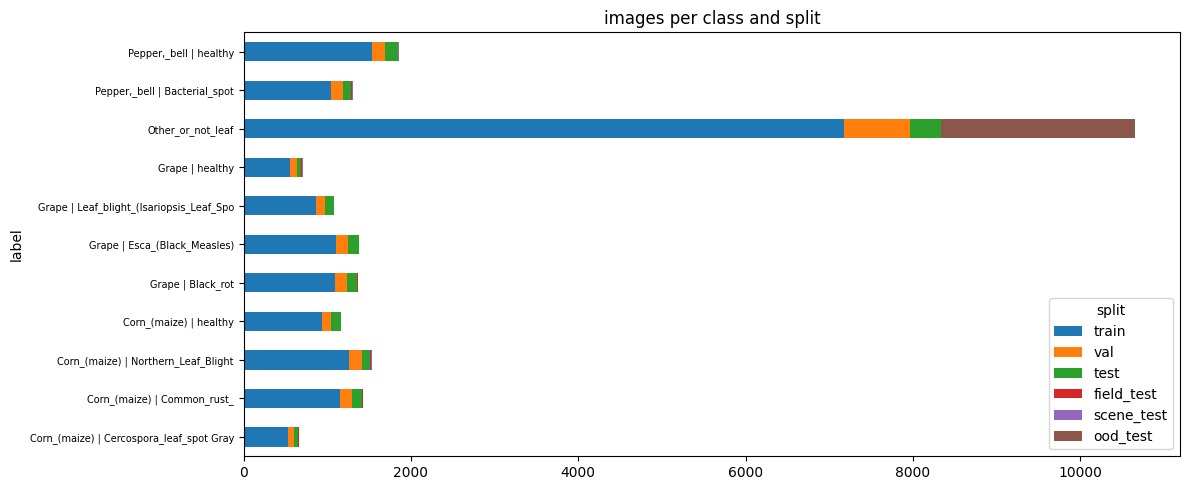

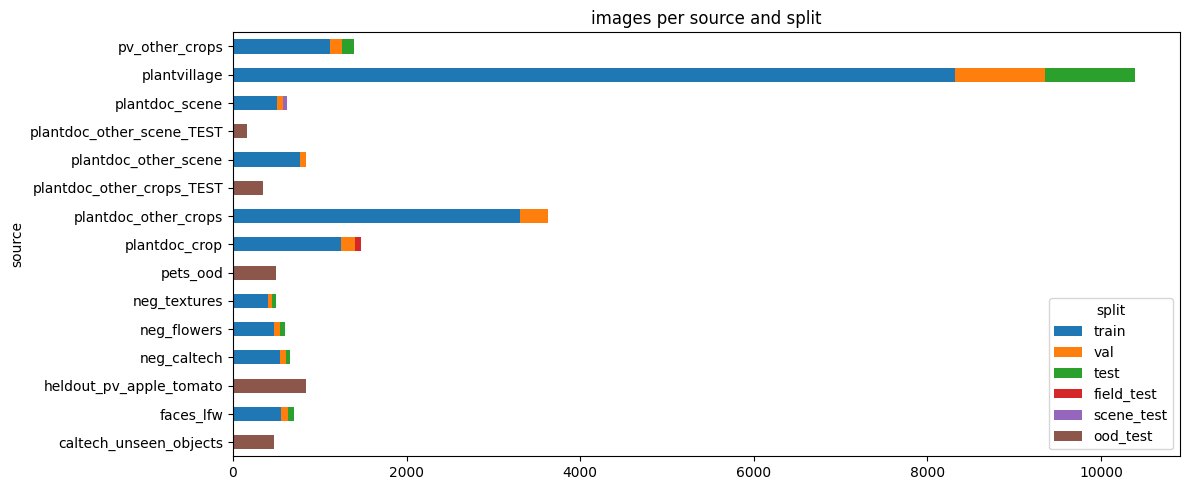

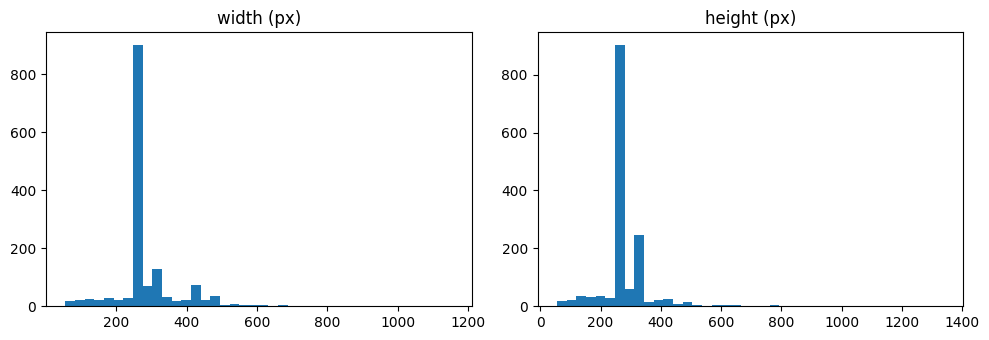

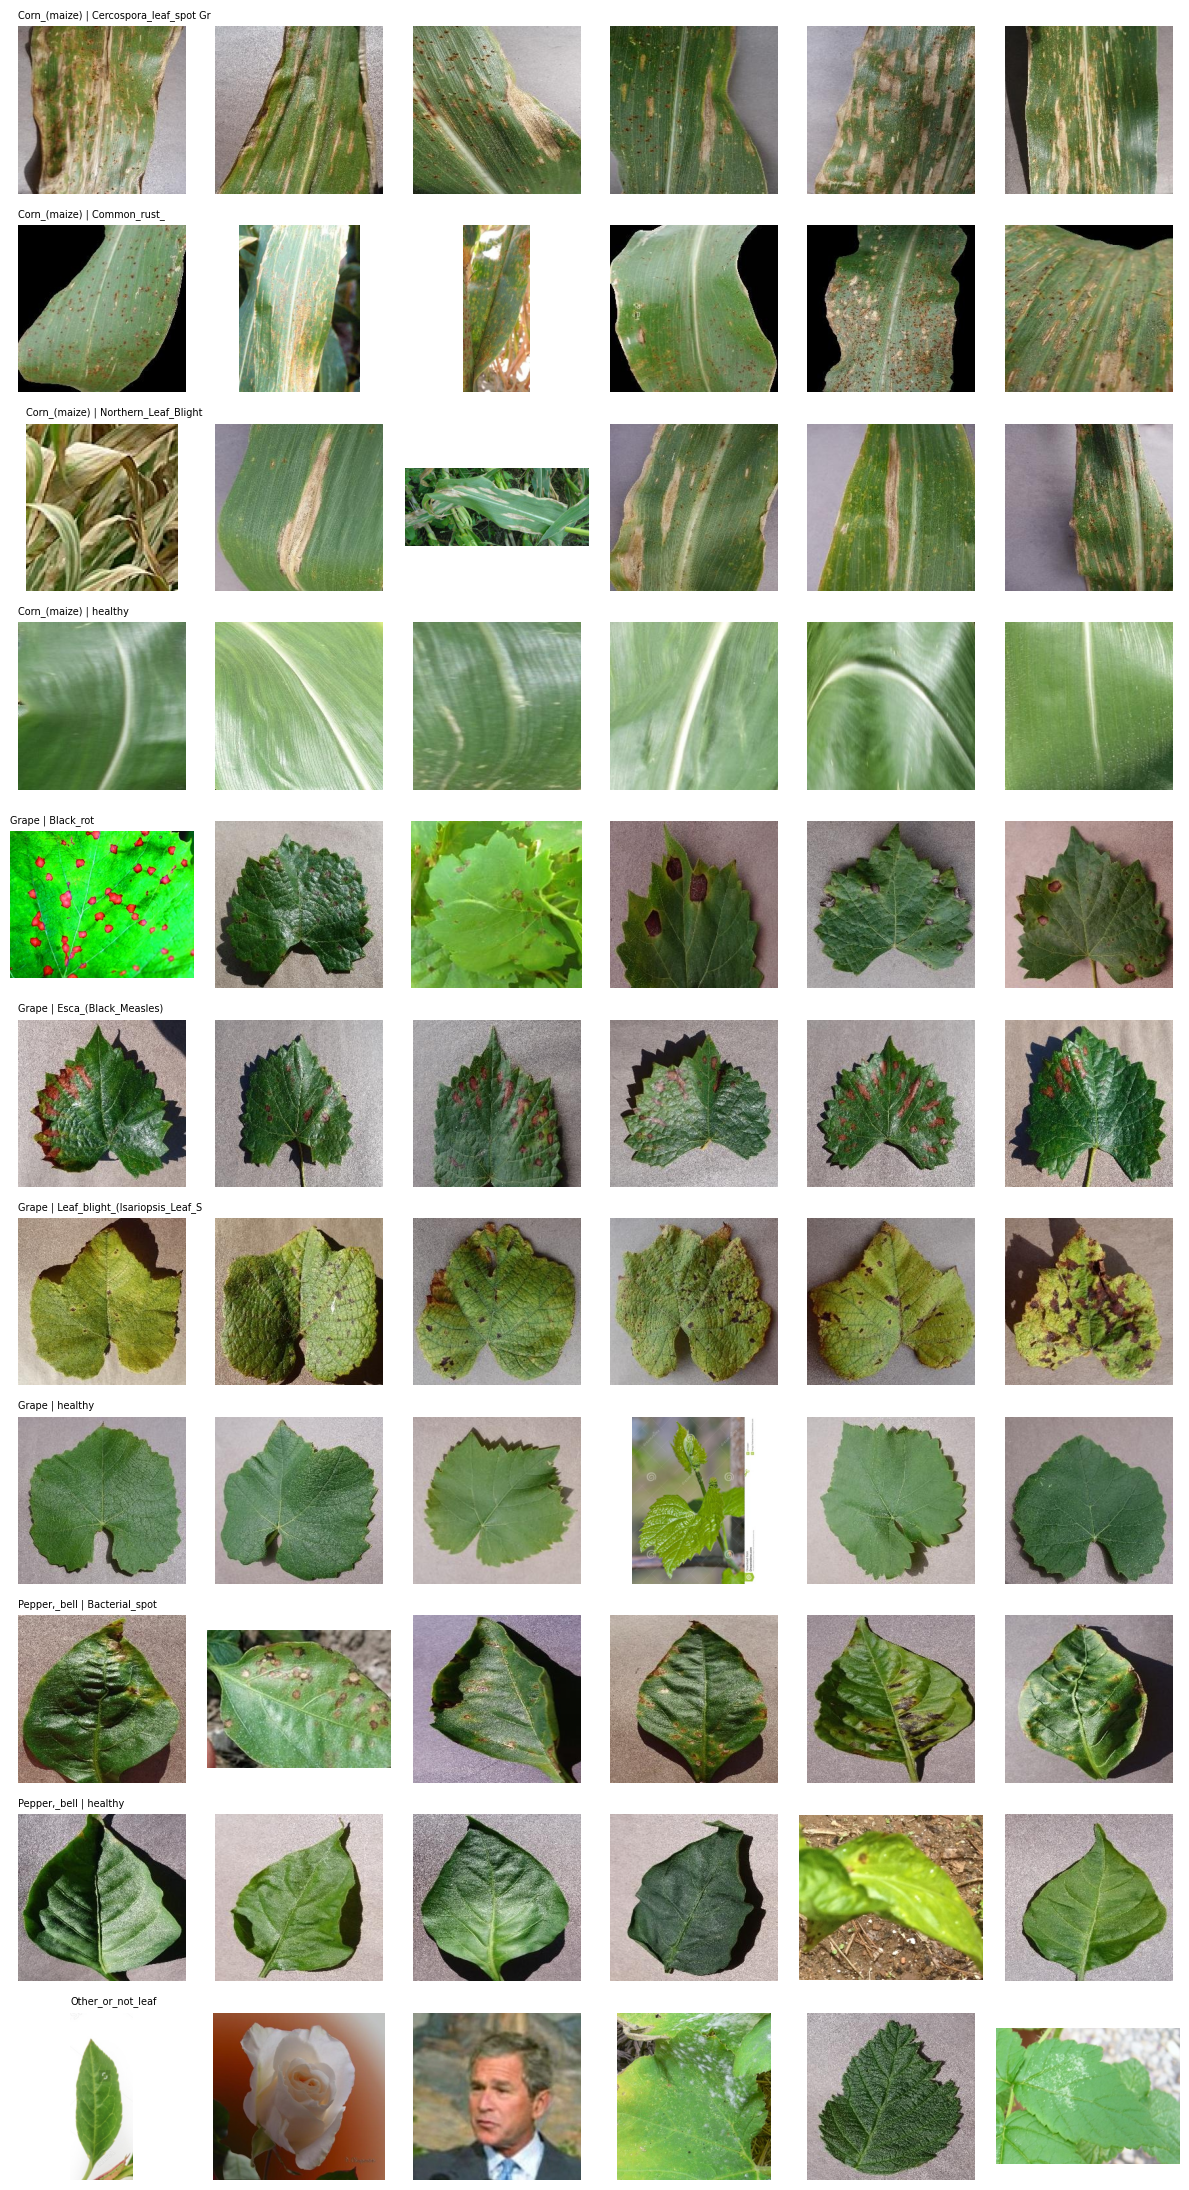

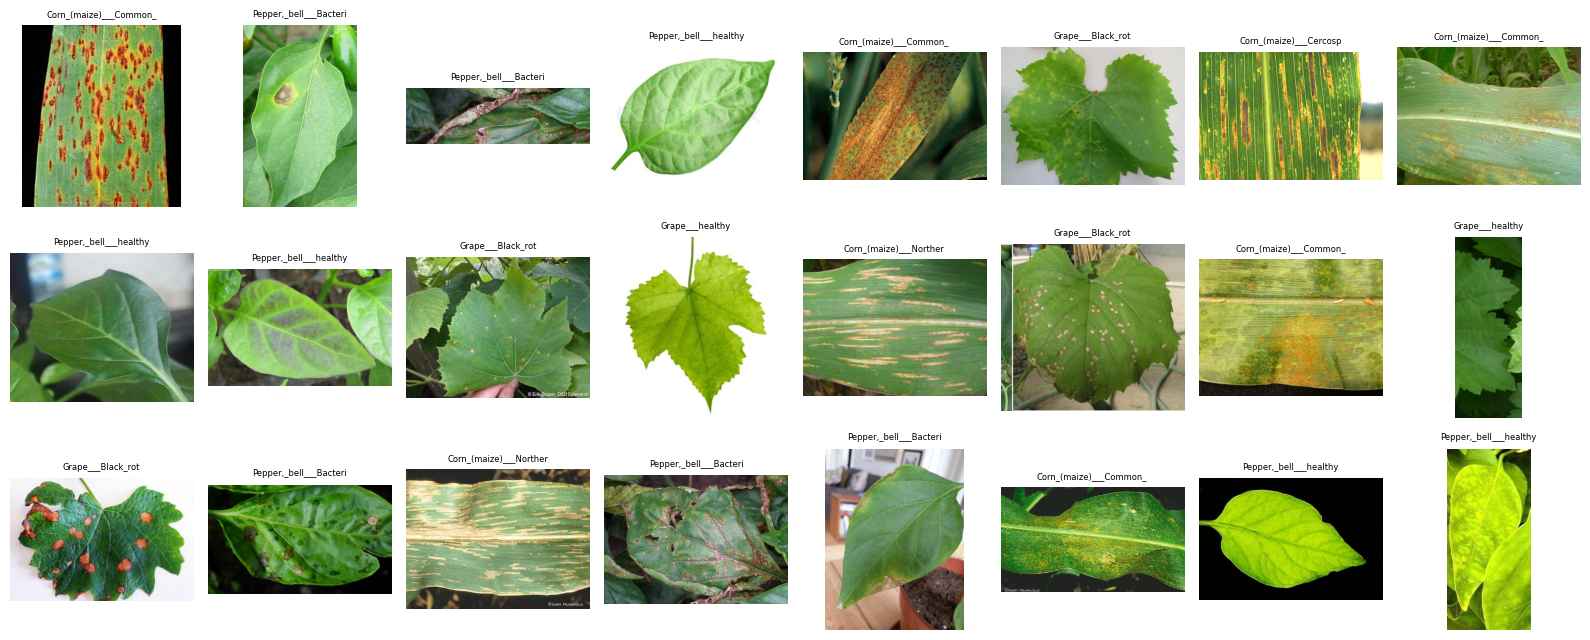

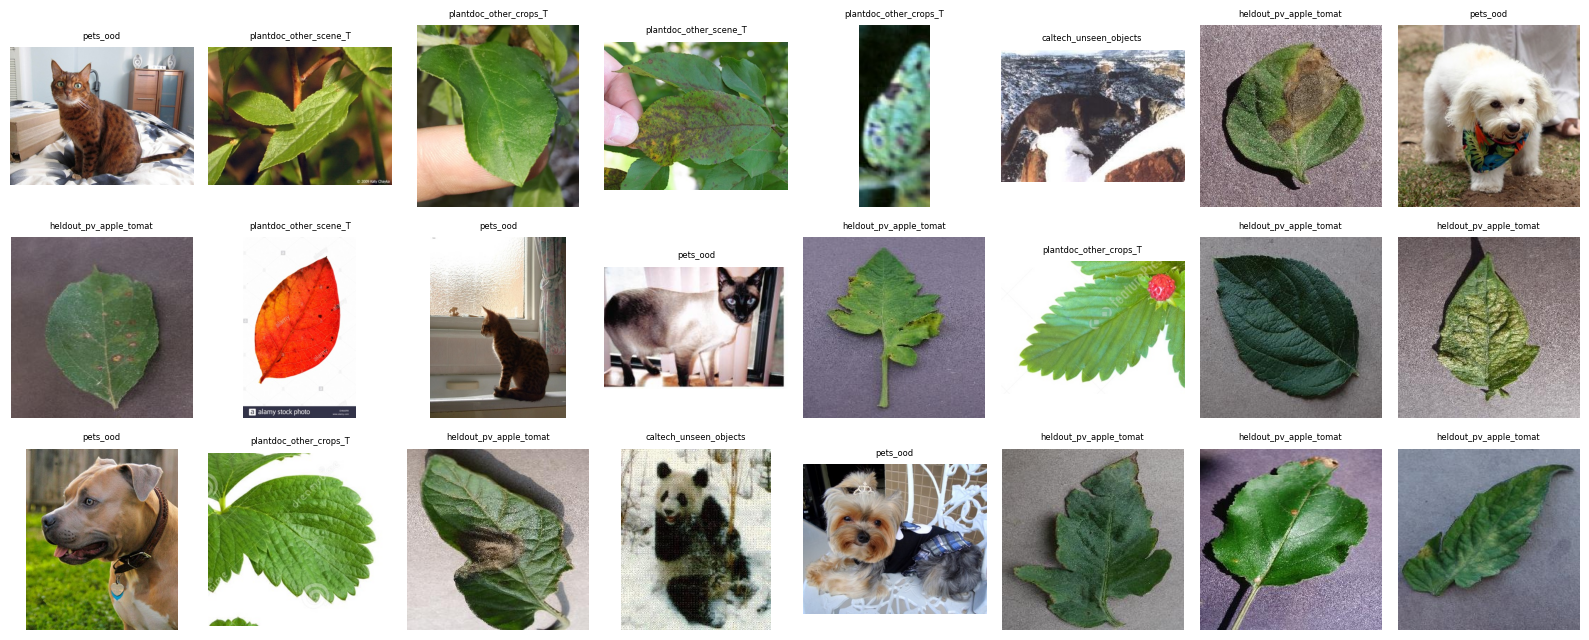

plots saved in /content/drive/MyDrive/plant-disease-v2/results


In [ ]:
# ---------- data QA (cleaning) + dataset plots ----------
import hashlib
import matplotlib.pyplot as plt
PLOTS = DRIVE_ROOT / "results"; PLOTS.mkdir(exist_ok=True)

# 1) every image must open and be big enough
bad = []
for r in df.itertuples():
    try:
        with Image.open(OUT / r.path) as im:
            im.verify()
        with Image.open(OUT / r.path) as im:
            if min(im.size) < 32: bad.append(r.Index)
    except Exception: bad.append(r.Index)
print("unreadable / tiny images dropped:", len(bad)); df = df.drop(index=bad).reset_index(drop=True)

# 2) exact duplicates that sit in DIFFERENT splits -> keep the best split (train > val > others) so test stays clean
df["md5"] = [hashlib.md5(open(OUT / p, "rb").read()).hexdigest() for p in df.path]
prio = {"train": 0, "val": 1, "test": 2, "field_test": 3, "scene_test": 4, "ood_test": 5}
nsplit = df.groupby("md5").split.transform("nunique")
dups = df[nsplit > 1].copy(); dups["pr"] = dups.split.map(prio)
best = dups.groupby("md5").pr.transform("min")
drop_idx = dups[dups.pr > best].index
print("cross-split exact duplicates removed:", len(drop_idx)); df = df.drop(index=drop_idx).reset_index(drop=True)

# 3) plots
order = ["train", "val", "test", "field_test", "scene_test", "ood_test"]
ct = pd.crosstab(df.label, df.split).reindex(columns=[c for c in order if c in set(df.split)], fill_value=0)
fig, ax = plt.subplots(figsize=(12, 5)); ct.plot.barh(stacked=True, ax=ax); ax.set_title("images per class and split")
ax.set_yticklabels([c.replace("___", " | ")[:40] for c in ct.index], fontsize=7); plt.tight_layout(); plt.savefig(PLOTS / "dataset_class_split.png", dpi=140); plt.show()
cs = pd.crosstab(df.source, df.split).reindex(columns=ct.columns, fill_value=0)
fig, ax = plt.subplots(figsize=(12, 5)); cs.plot.barh(stacked=True, ax=ax); ax.set_title("images per source and split"); plt.tight_layout()
plt.savefig(PLOTS / "dataset_source_split.png", dpi=140); plt.show()
sz = [Image.open(OUT / p).size for p in df.path.sample(min(1500, len(df)), random_state=0)]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5)); ax[0].hist([s[0] for s in sz], 40); ax[0].set_title("width (px)"); ax[1].hist([s[1] for s in sz], 40); ax[1].set_title("height (px)")
plt.tight_layout(); plt.savefig(PLOTS / "dataset_image_sizes.png", dpi=140); plt.show()
# sample grid: 4 random training images per class + 8 per 'Other' source family
fig, axs = plt.subplots(len(CLASS_NAMES), 6, figsize=(12, 2 * len(CLASS_NAMES)))
for i, c in enumerate(CLASS_NAMES):
    g = df[(df.label == c) & (df.split == "train")]; g = g.sample(min(6, len(g)), random_state=1)
    for j in range(6):
        axs[i, j].axis("off")
        if j < len(g): axs[i, j].imshow(Image.open(OUT / g.path.iloc[j]).convert("RGB"))
    axs[i, 0].set_title(c.replace("___", " | ")[:38], fontsize=7, loc="left")
plt.tight_layout(); plt.savefig(PLOTS / "dataset_samples_per_class.png", dpi=110); plt.show()
# pretty much the most useful check: look at the field crops and the unknown-image test set yourself
for name, sub in [("field_test", df[df.split == "field_test"]), ("ood_test", df[df.split == "ood_test"])]:
    sub = sub.sample(min(24, len(sub)), random_state=2) if len(sub) else sub
    fig, axs = plt.subplots(3, 8, figsize=(16, 6.5)); axs = axs.ravel()
    for a in axs: a.axis("off")
    for a, r in zip(axs, sub.itertuples()):
        a.imshow(Image.open(OUT / r.path).convert("RGB")); a.set_title((r.label if name == "field_test" else r.source)[:22], fontsize=6)
    plt.tight_layout(); plt.savefig(PLOTS / f"dataset_samples_{name}.png", dpi=110); plt.show()
print("plots saved in", PLOTS)


In [ ]:
# ---------- save manifest + zip to Drive ----------
df["y"] = df.label.map({c: i for i, c in enumerate(CLASS_NAMES)})
df.to_csv(OUT / "manifest.csv", index=False)
json.dump({"class_names": CLASS_NAMES, "other_index": CLASS_NAMES.index(OTHER), "group_sim": GROUP_SIM, "seed": SEED, "split_seed": SPLIT_SEED},
          open(OUT / "meta.json", "w"), indent=2)

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print("=== class x split ==="); print(pd.crosstab(df.label, df.split))
print("\n=== source x split ==="); print(pd.crosstab(df.source, df.split))

# ---- READINESS CHECK: refuse to save a dataset that would give meaningless results ----
t = pd.crosstab(df.label, df.split)
for sp_ in ("train", "val", "test"):
    assert (t.loc[IN_SCOPE, sp_] >= 20).all(), f"some in-scope class has < 20 images in {sp_}:\n{t[sp_]}"
for sp_ in ("field_test", "scene_test", "ood_test"): assert t[sp_].sum() > 0, f"{sp_} is empty"
print("\nREADY: all 10 classes have >= 20 images in train, val and test.")
print("  field_test per class (n is small -> judge field accuracy with the confidence intervals in notebook 05):")
print(t["field_test"][t["field_test"] > 0].to_string())

zip_path = shutil.make_archive(str(DRIVE_ROOT / "data_v2"), "zip", root_dir=str(OUT))
print("\nSaved:", zip_path, f"({os.path.getsize(zip_path) / 1e6:.0f} MB)")
print("Next: run notebooks 01-04 (one per model), then 05 for the comparison.")
# copies next to the zip: easy to inspect, and the md5 proves every model notebook uses the SAME split
import hashlib
for f in ("manifest.csv", "meta.json"): shutil.copy2(OUT / f, DRIVE_ROOT / f)
print("manifest md5:", hashlib.md5(open(OUT / "manifest.csv", "rb").read()).hexdigest())
print("Drive now holds:", ", ".join(sorted(p.name for p in DRIVE_ROOT.iterdir())))


=== class x split ===
split                                               field_test  ood_test  scene_test  test  train  val
label                                                                                                 
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot           4         0           3    51    529   72
Corn_(maize)___Common_rust_                                 10         0           3   120   1155  140
Corn_(maize)___Northern_Leaf_Blight                         11         0           5   100   1259  156
Corn_(maize)___healthy                                       0         0           0   115    932  115
Grape___Black_rot                                            8         0           6   119   1094  143
Grape___Esca_(Black_Measles)                                 0         0           0   136   1109  138
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)                   0         0           0   107    862  107
Grape___healthy                                    

## Browsable combined folder on Drive (optional, takes a while)

Creates `plant-disease-v2/combined_3crops/` so you can open it in Drive:

* `target_crops/<split>/<class>/` : ONLY corn / grape / pepper images (PlantVillage + PlantDoc combined) - the 10 classes the app will ever report.
* `negatives_not_predicted/<split>/<source>/` : other crops, faces, flowers, textures, pets. These are **never reported as a crop**; they only teach the model (and the thresholds) to answer "unsupported image".

The training notebooks do not need this folder (they use the zip, which is much faster). Set `EXPORT_BROWSABLE = False` to skip.

In [ ]:
from concurrent.futures import ThreadPoolExecutor
EXPORT_BROWSABLE = False   # optional slow copy (22k files). The old combined_3crops folder on Drive is now OUT OF DATE: delete it.

if EXPORT_BROWSABLE:
    DEST = DRIVE_ROOT / "combined_3crops"
    if DEST.exists(): shutil.rmtree(DEST)
    def safe(s): return re.sub(r"[^A-Za-z0-9_.-]+", "_", s)
    jobs = []
    for r in df.itertuples():
        if r.label == OTHER:
            d = DEST / "negatives_not_predicted" / r.split / safe(r.source)
        else:
            d = DEST / "target_crops" / r.split / safe(r.label)
        jobs.append((OUT / r.path, d / f"{safe(r.source)}__{Path(r.path).name}"))
    for d in {j[1].parent for j in jobs}: d.mkdir(parents=True, exist_ok=True)
    def cp(j): shutil.copy2(j[0], j[1])
    with ThreadPoolExecutor(8) as ex:
        for i, _ in enumerate(ex.map(cp, jobs), 1):
            if i % 3000 == 0: print(f"copied {i}/{len(jobs)}")
    shutil.copy2(OUT / "manifest.csv", DEST / "manifest.csv")
    (DEST / "README.txt").write_text(
        "target_crops/ = corn, grape, pepper only (PlantVillage + PlantDoc).\n"
        "negatives_not_predicted/ = other crops & non-leaf images; used so the model can reject unsupported photos.\n"
        "splits: train / val / test (PlantVillage, leak-free) | field_test (PlantDoc leaf crops) | scene_test (PlantDoc whole photos) | ood_test (unknown-image test).\n")
    print("Browsable folder:", DEST)
    print(df[df.label != OTHER].groupby(["label", "source"]).size().unstack(fill_value=0))

In [ ]:
# ---------- OPTIONAL: cache the raw downloads on Drive (PlantDoc, Flowers, DTD, Pets, LFW) ----------
# Only useful if you ever want to REBUILD the dataset without downloading ~3 GB again. data_v2.zip is all the model notebooks need.
CACHE_RAW = False   # a 5 GB tar on Drive; only set True if you have the space and want to rebuild without re-downloading
RAW_CACHE = DRIVE_ROOT / "raw_cache.tar"      # (also defined in cell 1; repeated so this cell works on its own)
if CACHE_RAW and not RAW_CACHE.exists():
    print("tarring raw downloads (a few minutes)...")
    subprocess.run(["tar", "--exclude=.git", "-cf", str(RAW_CACHE), "-C", str(RAW), "."], check=True)
    print("saved", RAW_CACHE, f"({os.path.getsize(RAW_CACHE) / 1e9:.1f} GB)")
else:
    print("raw cache already exists or CACHE_RAW=False")


raw cache already exists or CACHE_RAW=False


In [ ]:
# ================= VERIFY: is everything needed for training saved on Drive and consistent? (works in a fresh session) =================
from google.colab import drive; drive.mount("/content/drive")
import os, json, zipfile, hashlib, io
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image

D = Path("/content/drive/MyDrive/plant-disease-v2")
ok, bad = [], []
def check(name, cond, detail=""):
    (ok if cond else bad).append(name); print(("PASS  " if cond else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))
mb = lambda p: os.path.getsize(p) / 1e6

print("== 1. files on Drive ==")
need = {"data_v2.zip": 300, "manifest.csv": 0.5, "meta.json": 0.0001, "PlantVillage_color.tar": 500,
        "cache/pv_dinov2_s14_feats.npz": 5, "results/split_report_plantvillage.csv": 0.0001}
for f, mn in need.items():
    p = D / f; check(f"saved: {f}", p.exists() and mb(p) >= mn, f"{mb(p):.1f} MB" if p.exists() else "MISSING")
check("dataset QA plots saved (6 expected)", len(list((D / "results").glob("dataset_*.png"))) >= 6, f"{len(list((D / 'results').glob('dataset_*.png')))} found")
print("optional: raw_cache.tar", "present" if (D / "raw_cache.tar").exists() else "absent", "| combined_3crops", "present" if (D / "combined_3crops").exists() else "absent")

print("\n== 2. zip vs manifest ==")
zf = zipfile.ZipFile(D / "data_v2.zip"); names = set(zf.namelist())
man = pd.read_csv(D / "manifest.csv"); meta = json.load(open(D / "meta.json"))
check("zip is not corrupted", zf.testzip() is None)
zmd5 = hashlib.md5(zf.read("manifest.csv")).hexdigest()
check("manifest on Drive == manifest inside the zip", zmd5 == hashlib.md5(open(D / "manifest.csv", "rb").read()).hexdigest(), zmd5)
miss = [p for p in man.path if p not in names]
check("every manifest image exists in the zip", not miss, f"{len(man)} rows, {len(miss)} missing")

print("\n== 3. split ==")
cn = meta["class_names"]; tbl = pd.crosstab(man.label, man.split)
check("11 classes, 'Other_or_not_leaf' is LAST", len(cn) == 11 and cn[-1] == "Other_or_not_leaf" and meta["other_index"] == 10)
check("labels and y agree with class order", (man.y == man.label.map({c: i for i, c in enumerate(cn)})).all())
for s in ("train", "val", "test"):
    check(f"every in-scope class has >= 20 images in {s}", (tbl.loc[cn[:-1], s] >= 20).all(), f"min {tbl.loc[cn[:-1], s].min()}")
fr = tbl[["train", "val", "test"]].loc[cn[:-1]]; fr = fr.div(fr.sum(1), axis=0)
check("PlantVillage-style split is ~80/10/10 for every in-scope class", fr.val.between(.05, .2).all() and fr.test.between(.05, .2).all(),
      f"val {fr.val.min():.2f}-{fr.val.max():.2f}, test {fr.test.min():.2f}-{fr.test.max():.2f}")
ood_src = {"pets_ood", "heldout_pv_apple_tomato", "plantdoc_other_crops_TEST", "plantdoc_other_scene_TEST", "caltech_unseen_objects"}
check("unknown-image sources (pets, apple/tomato, other-crop test photos, unseen Caltech objects) appear ONLY in ood_test", set(man[man.source.isin(ood_src)].split) == {"ood_test"})
check("ood_test contains nothing else", set(man[man.split == "ood_test"].source) <= ood_src)
cal_o, cal_u = man[man.source == "neg_caltech"], man[man.source == "caltech_unseen_objects"]
check("Caltech101 present: >=300 'Other' training images and >=300 unseen-object OOD images", len(cal_o) >= 300 and len(cal_u) >= 300, f"{len(cal_o)} / {len(cal_u)}")
check("Caltech 'Other' images are only in train/val/test and labelled Other", set(cal_o.split) <= {"train", "val", "test"} and (cal_o.label == "Other_or_not_leaf").all())
check("Caltech OOD categories are DISJOINT from the categories used for training", not (set(cal_o.orig) & set(cal_u.orig)), f"{cal_o.orig.nunique()} train cats / {cal_u.orig.nunique()} unseen cats")
check("no source named like an OOD set is present in train/val/test", not (set(man[man.split.isin(["train", "val", "test"])].source) & ood_src))
check("field_test = PlantDoc crops only, scene_test = PlantDoc photos only",
      set(man[man.split == "field_test"].source) == {"plantdoc_crop"} and set(man[man.split == "scene_test"].source) == {"plantdoc_scene"})
if "group" in man:
    g = man[man.group >= 0]; check("no near-duplicate group crosses a split", (g.groupby("group").split.nunique() == 1).all(), f"GROUP_SIM={meta.get('group_sim')}")
pdm = man[man.source.str.startswith("plantdoc")].copy(); pdm["side"] = pdm.split.map(lambda s: s if s in ("train", "val") else "test")
check("PlantDoc: all crops of one photo stay in one split", (pdm.groupby("orig").side.nunique() == 1).all())
h = {p: hashlib.md5(zf.read(p)).hexdigest() for p in man.path}; man["h"] = man.path.map(h)
nd = man.groupby("h").split.nunique()
check("no exact-duplicate image across splits", (nd == 1).all(), f"{(nd > 1).sum()} duplicated groups")

print("\n== 4. preprocessing, cleaning, balance ==")
smp = man.sample(300, random_state=0); sz = []; rgb = True
for p in smp.path:
    im = Image.open(io.BytesIO(zf.read(p))); rgb &= im.mode == "RGB"; sz.append(min(im.size))
check("images are RGB JPEG, short side <= 320 px and >= 32 px", rgb and max(sz) <= 321 and min(sz) >= 32, f"short side {min(sz)}-{max(sz)}")
cnt = man[man.split == "train"].label.value_counts().reindex(cn); w = len(man[man.split == "train"]) / (len(cn) * cnt)
print(pd.DataFrame({"train n": cnt, "loss weight": w.round(2)}).to_string())
print(f"-> imbalance {cnt.max() / cnt.min():.1f}x is handled by the class-weighted loss in 01-04 (augmentation is applied on the fly to TRAIN only)")

print("\n== 5. model outputs ==")
md5s = {}
for m in ["efficientnet_b0", "mobilenetv3_large", "dinov2_vit_s14", "dinov2_vit_b14", "convnext_tiny"]:
    files = [f"checkpoints/{m}_best.pth", f"checkpoints/{m}_ood_stats.npz", f"checkpoints/{m}_ood_thresholds.json", f"results/{m}_metrics.json",
             f"results/{m}_history.csv", f"results/{m}_curves.png", f"results/{m}_confusion.png", f"results/{m}_outputs.npz", f"results/{m}_cm_field.png"]
    have = [(D / f).exists() for f in files]
    if not any(have): print(f"  {m:20s} not trained yet"); continue
    print(f"  {m:20s} {sum(have)}/{len(files)} files" + ("" if all(have) else "  MISSING: " + ", ".join(f.split('/')[-1] for f, e in zip(files, have) if not e)))
    if (D / f"results/{m}_metrics.json").exists(): md5s[m] = json.load(open(D / f"results/{m}_metrics.json")).get("manifest_md5")
if md5s: check("all trained models used THIS manifest (same split)", all(v == zmd5 for v in md5s.values()), str(md5s))

print(f"\n{len(ok)} checks passed, {len(bad)} failed.")
print("ALL GOOD - safe to start training." if not bad else "FIX FIRST: " + "; ".join(bad))
print("manifest md5 (must show up in every model notebook):", zmd5)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
== 1. files on Drive ==
PASS  saved: data_v2.zip   [628.2 MB]
PASS  saved: manifest.csv   [4.2 MB]
PASS  saved: meta.json   [0.0 MB]
PASS  saved: PlantVillage_color.tar   [908.1 MB]
PASS  saved: cache/pv_dinov2_s14_feats.npz   [17.2 MB]
PASS  saved: results/split_report_plantvillage.csv   [0.0 MB]
PASS  dataset QA plots saved (6 expected)   [6 found]
optional: raw_cache.tar absent | combined_3crops absent

== 2. zip vs manifest ==
PASS  zip is not corrupted
PASS  manifest on Drive == manifest inside the zip   [c0c74aae5361191f93208dcd44c3a7f4]
PASS  every manifest image exists in the zip   [23145 rows, 0 missing]

== 3. split ==
PASS  11 classes, 'Other_or_not_leaf' is LAST
PASS  labels and y agree with class order
PASS  every in-scope class has >= 20 images in train   [min 529]
PASS  every in-scope class has >= 20 images in val   [min 72]
PASS  every in-scop